# Chương 4 — Thực nghiệm và kết quả

Chương này đánh giá Diffusion Maps trên Swiss Roll và MNIST, đồng thời so sánh với PCA và t-SNE. Quy trình gồm bốn bước: chuẩn bị dữ liệu, lựa chọn băng thông kernel, xây dựng biểu diễn hai chiều và đánh giá bằng các tiêu chí hình học thống nhất.

Mọi thao tác ngẫu nhiên sử dụng SEED = 42. Nhãn MNIST chỉ được dùng để trực quan hóa và đánh giá sau khi hoàn thành giảm chiều; nhãn không tham gia xây dựng Diffusion Maps, PCA hoặc t-SNE.

In [40]:
# ── Environment setup ─────────────────────────────────────────────────────
import os
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from IPython.display import display
from scipy.linalg import eigh
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist, pdist
from scipy.special import logsumexp
from scipy.stats import spearmanr
from sklearn.datasets import make_swiss_roll
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from tensorflow.keras.datasets import mnist

SEED = 42
np.random.seed(SEED)

OUTPUT_DIR = '/content/pictures'
os.makedirs(OUTPUT_DIR, exist_ok=True)

matplotlib.rcParams.update({'font.family': 'serif', 'font.size': 8.2, 'axes.titlesize': 8.8, 'axes.labelsize': 8.2, 'xtick.labelsize': 7.0, 'ytick.labelsize': 7.0, 'legend.fontsize': 7.0, 'figure.dpi': 140, 'savefig.dpi': 600, 'axes.linewidth': 0.7, 'axes.spines.top': False, 'axes.spines.right': False, 'xtick.direction': 'out', 'ytick.direction': 'out', 'pdf.fonttype': 42, 'ps.fonttype': 42, 'text.usetex': False})

CB = {'orange': '#E69F00', 'sky': '#56B4E9', 'green': '#009E73', 'yellow': '#F0E442', 'blue': '#0072B2', 'vermilion': '#D55E00', 'pink': '#CC79A7', 'black': '#000000'}
METHOD_COLORS = {'Diffusion Maps': CB['blue'], 'PCA': CB['vermilion'], 't-SNE': CB['green']}

print('Environment ready.')

Environment ready.


## 4.1. Tổng quan dữ liệu và thiết lập thực nghiệm

Thực nghiệm sử dụng hai bộ dữ liệu có đặc điểm hình học khác nhau.

### Swiss Roll

Swiss Roll gồm 600 điểm trên một đa tạp hai chiều được nhúng trong $\mathbb{R}^3$. Dữ liệu được tạo với nhiễu Gaussian $\sigma=0.3$ và random_state = 42. Ba tọa độ quan sát được chuẩn hóa z-score trước khi đưa vào các thuật toán.

Tọa độ nội tại tham chiếu được xác định bởi $Z_{\mathrm{SR}}=(s(t),h)$, trong đó

$$
s(t)=\frac{1}{2}\left[t\sqrt{1+t^2}+\operatorname{asinh}(t)\right].
$$

### MNIST

Tập MNIST con gồm 600 ảnh, với 60 ảnh được lấy ngẫu nhiên từ mỗi chữ số. Mỗi ảnh $28\times28$ được chuyển thành vectơ 784 chiều và chuẩn hóa từ $[0,255]$ về $[0,1]$. Cùng một tập mẫu được sử dụng cho cả ba phương pháp.

In [41]:
# ── Dataset generation ────────────────────────────────────────────────────
N_SR = 600
N_PER_DIGIT = 60
N_MNIST = 10 * N_PER_DIGIT

X_sr_raw, t_sr = make_swiss_roll(n_samples=N_SR, noise=0.3, random_state=SEED)
X_sr = StandardScaler().fit_transform(X_sr_raw)
h_sr = X_sr_raw[:, 1]
s_sr = 0.5 * (t_sr * np.sqrt(1.0 + t_sr ** 2) + np.arcsinh(t_sr))
X_sr_reference = np.column_stack((s_sr, h_sr))

(X_mnist_train, y_mnist_train), (_, _) = mnist.load_data()
data_rng = np.random.default_rng(SEED)
mnist_indices = np.concatenate([data_rng.choice(np.flatnonzero(y_mnist_train == digit), size=N_PER_DIGIT, replace=False) for digit in range(10)])
mnist_indices = mnist_indices[data_rng.permutation(len(mnist_indices))]
X_mnist_images = X_mnist_train[mnist_indices]
y_mnist = y_mnist_train[mnist_indices].astype(int)
X_mnist = X_mnist_images.reshape(N_MNIST, 784).astype(np.float64) / 255.0

print(f'Swiss Roll: n={X_sr.shape[0]}, d={X_sr.shape[1]}')
print(f'MNIST:      n={X_mnist.shape[0]}, d={X_mnist.shape[1]}')
print('MNIST class counts:', np.bincount(y_mnist, minlength=10).tolist())

Swiss Roll: n=600, d=3
MNIST:      n=600, d=784
MNIST class counts: [60, 60, 60, 60, 60, 60, 60, 60, 60, 60]


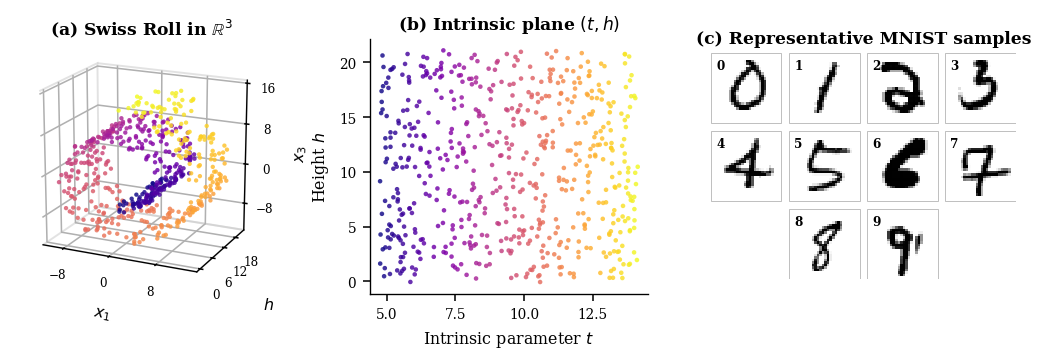

Saved: /content/pictures/fig_datasets.pdf


In [42]:
# ── Dataset overview ──────────────────────────────────────────────────────
mnist_examples = [X_mnist_images[np.flatnonzero(y_mnist == digit)[0]] for digit in range(10)]
digit_positions = [(0, 0), (0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (1, 2), (1, 3), (2, 1), (2, 2)]
tile_size = 28
tile_gap = 3
mnist_canvas = np.zeros((3 * tile_size + 2 * tile_gap, 4 * tile_size + 3 * tile_gap))

for digit, (row, column) in enumerate(digit_positions):
    y_start = row * (tile_size + tile_gap)
    x_start = column * (tile_size + tile_gap)
    mnist_canvas[y_start:y_start + tile_size, x_start:x_start + tile_size] = mnist_examples[digit]

t_norm = mcolors.Normalize(vmin=t_sr.min(), vmax=t_sr.max())
fig = plt.figure(figsize=(7.5, 2.60))
ax1 = fig.add_axes([0.015, 0.17, 0.275, 0.70], projection='3d')
ax2 = fig.add_axes([0.370, 0.17, 0.265, 0.70])
ax3 = fig.add_axes([0.695, 0.17, 0.290, 0.70])

ax1.scatter(X_sr_raw[:, 0], X_sr_raw[:, 1], X_sr_raw[:, 2], c=t_sr, cmap='plasma', norm=t_norm, s=5, alpha=0.82, linewidths=0, depthshade=False, rasterized=True)
for pane in [ax1.xaxis.pane, ax1.yaxis.pane, ax1.zaxis.pane]:
    pane.fill = False
    pane.set_edgecolor('0.78')
ax1.grid(True, linewidth=0.25, alpha=0.28)
ax1.set_xlabel(r'$x_1$', labelpad=-2)
ax1.set_ylabel(r'$h$', labelpad=0)
ax1.set_zlabel(r'$x_3$', labelpad=-2)
ax1.tick_params(labelsize=6.2, pad=-1)
ax1.xaxis.set_major_locator(ticker.MaxNLocator(4))
ax1.yaxis.set_major_locator(ticker.MaxNLocator(4))
ax1.zaxis.set_major_locator(ticker.MaxNLocator(4))
ax1.set_box_aspect((1.05, 0.78, 1.00))
ax1.view_init(elev=18, azim=-65)
ax1.set_title(r'(a) Swiss Roll in $\mathbb{R}^3$', fontweight='bold', pad=1)

ax2.scatter(t_sr, h_sr, c=t_sr, cmap='plasma', norm=t_norm, s=5.5, alpha=0.82, linewidths=0, rasterized=True)
ax2.set_xlabel(r'Intrinsic parameter $t$')
ax2.set_ylabel(r'Height $h$')
ax2.set_title(r'(b) Intrinsic plane $(t,h)$', fontweight='bold', pad=5)
ax2.xaxis.set_major_locator(ticker.MaxNLocator(5))
ax2.yaxis.set_major_locator(ticker.MaxNLocator(5))
ax2.margins(x=0.04, y=0.05)

ax3.imshow(mnist_canvas, cmap='gray_r', vmin=0, vmax=255, interpolation='nearest', rasterized=True)
for digit, (row, column) in enumerate(digit_positions):
    y_start = row * (tile_size + tile_gap)
    x_start = column * (tile_size + tile_gap)
    ax3.add_patch(mpatches.Rectangle((x_start - 0.5, y_start - 0.5), tile_size, tile_size, fill=False, edgecolor='0.72', linewidth=0.45))
    ax3.text(x_start + 1.5, y_start + 4.5, str(digit), fontsize=6.2, fontweight='bold', color='black', ha='left', va='center', bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.78, 'pad': 0.25})
ax3.set_title('(c) Representative MNIST samples', fontweight='bold', pad=5)
ax3.set_axis_off()

overview_path = os.path.join(OUTPUT_DIR, 'fig_datasets.pdf')
fig.savefig(overview_path, dpi=600, bbox_inches='tight', pad_inches=0.04, facecolor='white')
plt.show()
print('Saved:', overview_path)

## 4.2. Xây dựng Diffusion Maps và lựa chọn băng thông

Với dữ liệu $X=\{x_i\}_{i=1}^{n}$, Diffusion Maps được xây dựng từ kernel Gaussian trên một đồ thị lân cận. Hiệu chỉnh mật độ với $\alpha=1$ được thực hiện qua

$$
q_i=\sum_jW_{ij},\qquad
\widetilde W_{ij}=\frac{W_{ij}}{q_i^\alpha q_j^\alpha},
$$

sau đó chuẩn hóa theo hàng để thu được ma trận Markov $P$. Biểu diễn hai chiều tại thời gian khuếch tán $t=1$ là

$$
\Phi_t(x_i)=\left(\lambda_1^t\psi_1(i),\lambda_2^t\psi_2(i)\right).
$$

Bản triển khai sử dụng đồ thị 64 láng giềng gần nhất. Do mật độ mẫu của MNIST không đồng đều, kernel sử dụng băng thông cục bộ. Gọi $\rho_i$ là khoảng cách từ $x_i$ đến láng giềng gần thứ 10. Kernel được đối xứng hóa theo hợp của hai quan hệ lân cận:

$$
W_{ij}=\begin{cases}
\exp\left(-\dfrac{\lVert x_i-x_j\rVert^2}{4\varepsilon\rho_i\rho_j}\right), & j\in\mathcal{N}_{64}(i)\ \text{hoặc}\ i\in\mathcal{N}_{64}(j),\\
0, & \text{ngược lại}.
\end{cases}
$$

Băng thông toàn cục $\varepsilon$ được lựa chọn bằng thủ tục Berry–Giannakis–Harlim (BGH). Với $\mathcal{E}$ là tập cạnh có hướng của đồ thị k-NN,

$$
S(\varepsilon)=\sum_{(i,j)\in\mathcal{E}}\exp\left(-\frac{\lVert x_i-x_j\rVert^2}{4\varepsilon\rho_i\rho_j}\right),
$$

giá trị được chọn tại vị trí cực đại của độ dốc $d\log S(\varepsilon)/d\log\varepsilon$. Thủ tục này không sử dụng nhãn hoặc chỉ số đánh giá đầu ra.

In [43]:
# ── Diffusion Maps core ───────────────────────────────────────────────────
ALPHA = 1.0
DIFFUSION_TIME = 1
EMBEDDING_DIM = 2
N_EIGENVECTORS = 8
BANDWIDTH_K = 64
LOCAL_SCALE_K = 10
MIN_SUPPORT_FRACTION = 0.02

def prepare_knn_graph(X, n_neighbors=64, local_scale_neighbors=10):
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2 or X.shape[0] < 3:
        raise ValueError('X must be a two-dimensional array with at least three samples.')
    if not np.all(np.isfinite(X)):
        raise ValueError('X contains NaN or infinite values.')
    if n_neighbors < 1 or n_neighbors >= X.shape[0]:
        raise ValueError('n_neighbors must satisfy 1 <= n_neighbors < n_samples.')
    if local_scale_neighbors < 1 or local_scale_neighbors > n_neighbors:
        raise ValueError('local_scale_neighbors must satisfy 1 <= local_scale_neighbors <= n_neighbors.')
    model = NearestNeighbors(n_neighbors=n_neighbors + 1, algorithm='auto', n_jobs=-1).fit(X)
    distances, indices = model.kneighbors(X, return_distance=True)
    distances = distances[:, 1:]
    indices = indices[:, 1:]
    local_scales = np.maximum(distances[:, local_scale_neighbors - 1], np.finfo(np.float64).eps)
    scaled_squared_distances = (distances ** 2) / (local_scales[:, None] * local_scales[indices])
    rows = np.repeat(np.arange(X.shape[0]), n_neighbors)
    columns = indices.ravel()
    directed_squared_distances = scaled_squared_distances.ravel()
    directed_distance_matrix = np.full((X.shape[0], X.shape[0]), np.inf, dtype=np.float64)
    directed_distance_matrix[rows, columns] = directed_squared_distances
    symmetric_distance_matrix = np.minimum(directed_distance_matrix, directed_distance_matrix.T)
    np.fill_diagonal(symmetric_distance_matrix, 0.0)
    adjacency = np.isfinite(symmetric_distance_matrix).astype(np.int8)
    n_components = connected_components(csr_matrix(adjacency), directed=False, return_labels=False)
    if n_components != 1:
        raise RuntimeError(f'The symmetrised {n_neighbors}-NN graph has {n_components} connected components.')
    return {'scaled_squared_distances': symmetric_distance_matrix, 'bgh_distances': np.concatenate((directed_squared_distances, np.zeros(X.shape[0]))), 'local_scales': local_scales, 'n_neighbors': int(n_neighbors), 'local_scale_neighbors': int(local_scale_neighbors), 'n_components': int(n_components)}

def select_epsilon_bgh(squared_distances, epsilons=None):
    squared_distances = np.asarray(squared_distances, dtype=np.float64).ravel()
    if squared_distances.size == 0 or not np.all(np.isfinite(squared_distances)) or np.any(squared_distances < 0):
        raise ValueError('squared_distances must be a non-empty finite non-negative array.')
    if epsilons is None:
        epsilons = 2.0 ** np.arange(-40.0, 41.0, 1.0)
    epsilons = np.sort(np.asarray(epsilons, dtype=np.float64))
    if epsilons.ndim != 1 or epsilons.size < 3 or not np.all(np.isfinite(epsilons)) or np.any(epsilons <= 0):
        raise ValueError('epsilons must contain at least three finite positive values.')
    log_kernel_sums = np.array([logsumexp(-squared_distances / (4.0 * epsilon)) for epsilon in epsilons])
    log_epsilon = np.log(epsilons)
    slopes = np.diff(log_kernel_sums) / np.diff(log_epsilon)
    selected_index = int(np.argmax(slopes))
    if selected_index == 0 or selected_index == len(slopes) - 1:
        raise RuntimeError('The BGH maximum lies on the epsilon-grid boundary; extend the grid before continuing.')
    epsilon = float(epsilons[selected_index])
    dimension_estimate = float(np.round(2.0 * slopes[selected_index]))
    return {'epsilon': epsilon, 'epsilon_grid': epsilons, 'log_kernel_sums': log_kernel_sums, 'slopes': slopes, 'selected_index': selected_index, 'dimension_estimate': dimension_estimate}

def build_diffusion_map(X, graph, epsilon, alpha=1.0, diffusion_time=1, embedding_dim=2, n_eigenvectors=8):
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2 or X.shape[0] < 3:
        raise ValueError('X must be a two-dimensional array with at least three samples.')
    if not np.all(np.isfinite(X)):
        raise ValueError('X contains NaN or infinite values.')
    if not np.isfinite(epsilon) or epsilon <= 0:
        raise ValueError('epsilon must be finite and positive.')
    if not isinstance(diffusion_time, (int, np.integer)) or diffusion_time < 0:
        raise ValueError('diffusion_time must be a non-negative integer.')
    D2 = np.asarray(graph['scaled_squared_distances'], dtype=np.float64)
    if D2.shape != (X.shape[0], X.shape[0]):
        raise ValueError('The graph distance matrix does not match X.')
    edge_mask = np.isfinite(D2)
    W = np.zeros_like(D2)
    W[edge_mask] = np.exp(-D2[edge_mask] / (4.0 * epsilon))
    W = np.maximum(W, W.T)
    np.fill_diagonal(W, 1.0)
    kernel_adjacency = (W > 1e-14).astype(np.int8)
    kernel_components = connected_components(csr_matrix(kernel_adjacency), directed=False, return_labels=False)
    if kernel_components != 1:
        raise RuntimeError(f'The weighted kernel has {kernel_components} numerical connected components; increase epsilon.')
    tiny = np.finfo(np.float64).eps
    q = np.maximum(W.sum(axis=1), tiny)
    W_tilde = W / np.outer(q ** alpha, q ** alpha)
    degree = np.maximum(W_tilde.sum(axis=1), tiny)
    P = W_tilde / degree[:, None]
    degree_sqrt = np.sqrt(degree)
    S = W_tilde / np.outer(degree_sqrt, degree_sqrt)
    S = 0.5 * (S + S.T)
    n_samples = X.shape[0]
    n_nontrivial = min(max(n_eigenvectors, embedding_dim), n_samples - 1)
    n_pairs = n_nontrivial + 1
    eigenvalues, symmetric_eigenvectors = eigh(S, subset_by_index=[n_samples - n_pairs, n_samples - 1])
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    symmetric_eigenvectors = symmetric_eigenvectors[:, order]
    right_eigenvectors = symmetric_eigenvectors / degree_sqrt[:, None]
    trivial_scale = float(np.mean(right_eigenvectors[:, 0]))
    if abs(trivial_scale) <= tiny:
        raise RuntimeError('The trivial eigenvector could not be normalised.')
    right_eigenvectors = right_eigenvectors / trivial_scale
    nontrivial_values = eigenvalues[1:n_nontrivial + 1]
    nontrivial_vectors = right_eigenvectors[:, 1:n_nontrivial + 1]
    embedding = nontrivial_vectors[:, :embedding_dim] * (nontrivial_values[:embedding_dim] ** diffusion_time)
    if not np.all(np.isfinite(embedding)):
        raise RuntimeError('The Diffusion Maps embedding contains non-finite values.')
    support_fraction = 1.0 / (X.shape[0] * np.sum((nontrivial_vectors[:, :embedding_dim] / np.linalg.norm(nontrivial_vectors[:, :embedding_dim], axis=0, keepdims=True)) ** 4, axis=0))
    return {'embedding': embedding, 'eigenvalues': nontrivial_values, 'eigenvectors': nontrivial_vectors, 'support_fraction': support_fraction, 'P': P, 'W': W, 'W_tilde': W_tilde, 'epsilon': float(epsilon), 'alpha': float(alpha), 'diffusion_time': int(diffusion_time), 'n_neighbors': graph['n_neighbors'], 'local_scale_neighbors': graph['local_scale_neighbors'], 'kernel_components': int(kernel_components)}

def fit_diffusion_map(X, n_neighbors=64, local_scale_neighbors=10, alpha=1.0, diffusion_time=1, embedding_dim=2, n_eigenvectors=8):
    graph = prepare_knn_graph(X, n_neighbors=n_neighbors, local_scale_neighbors=local_scale_neighbors)
    bgh = select_epsilon_bgh(graph['bgh_distances'])
    result = build_diffusion_map(X, graph=graph, epsilon=bgh['epsilon'], alpha=alpha, diffusion_time=diffusion_time, embedding_dim=embedding_dim, n_eigenvectors=n_eigenvectors)
    if np.any(result['support_fraction'] < MIN_SUPPORT_FRACTION):
        raise RuntimeError(f'Localised diffusion eigenvector detected: support fractions={result["support_fraction"]}.')
    return result, graph, bgh

GRAPH_SR = prepare_knn_graph(X_sr, n_neighbors=BANDWIDTH_K, local_scale_neighbors=LOCAL_SCALE_K)
GRAPH_MNIST = prepare_knn_graph(X_mnist, n_neighbors=BANDWIDTH_K, local_scale_neighbors=LOCAL_SCALE_K)
bgh_sr = select_epsilon_bgh(GRAPH_SR['bgh_distances'])
bgh_mnist = select_epsilon_bgh(GRAPH_MNIST['bgh_distances'])
EPSILON_SR = bgh_sr['epsilon']
EPSILON_MNIST = bgh_mnist['epsilon']

bandwidth_df = pd.DataFrame([{'Dataset': 'Swiss Roll', 'Graph k': BANDWIDTH_K, 'Local-scale k': LOCAL_SCALE_K, 'epsilon': EPSILON_SR, 'BGH dimension estimate': bgh_sr['dimension_estimate'], 'Connected components': GRAPH_SR['n_components']}, {'Dataset': 'MNIST', 'Graph k': BANDWIDTH_K, 'Local-scale k': LOCAL_SCALE_K, 'epsilon': EPSILON_MNIST, 'BGH dimension estimate': bgh_mnist['dimension_estimate'], 'Connected components': GRAPH_MNIST['n_components']}])
display(bandwidth_df.round(6))

,Dataset,Graph k,Local-scale k,epsilon,BGH dimension estimate,Connected components
0,Swiss Roll,64,10,0.2500,2.0,1
1,MNIST,64,10,0.0625,4.0,1


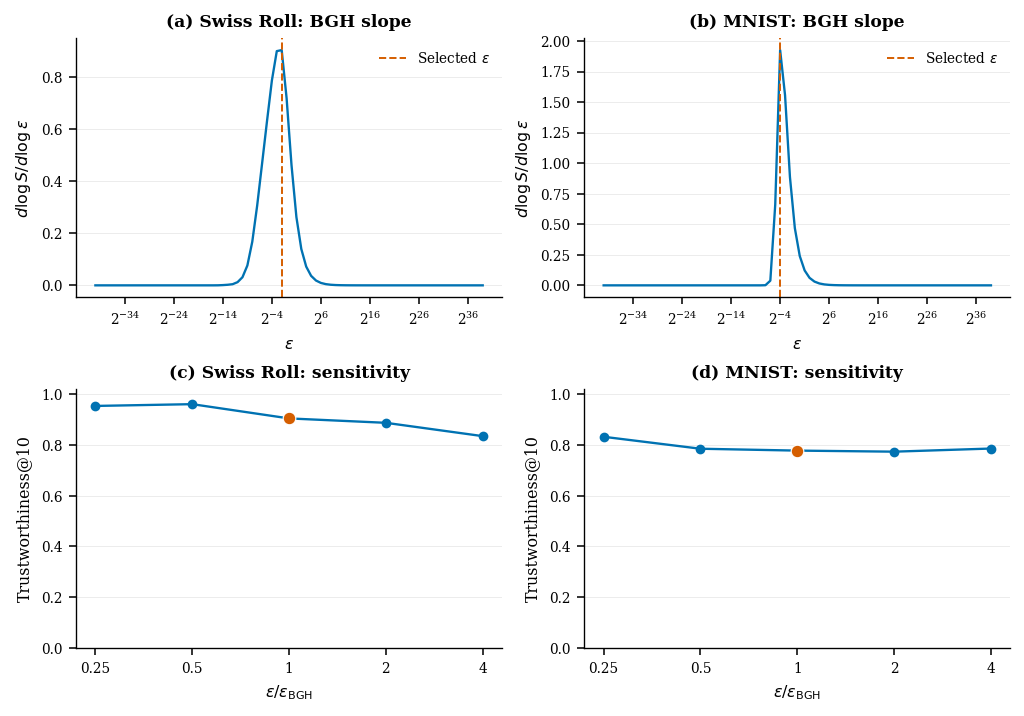

,factor,epsilon,trustworthiness
0,0.25,0.0625,0.9538
1,0.50,0.1250,0.9608
2,1.00,0.2500,0.9046
3,2.00,0.5000,0.8872
4,4.00,1.0000,0.8347


,factor,epsilon,trustworthiness
0,0.25,0.0156,0.8322
1,0.50,0.0312,0.7851
2,1.00,0.0625,0.7777
3,2.00,0.1250,0.7735
4,4.00,0.2500,0.7858


Saved: /content/pictures/fig_bandwidth_selection.pdf


In [44]:
# ── Bandwidth diagnostics and sensitivity ─────────────────────────────────
EPS_FACTORS = np.array([0.25, 0.50, 1.00, 2.00, 4.00])

def diffusion_sensitivity(X, X_reference, graph, epsilon, factors, n_neighbors=10):
    records = []
    for factor in factors:
        result = build_diffusion_map(X, graph=graph, epsilon=float(factor * epsilon), alpha=ALPHA, diffusion_time=DIFFUSION_TIME, embedding_dim=EMBEDDING_DIM, n_eigenvectors=N_EIGENVECTORS)
        score = trustworthiness(X_reference, result['embedding'], n_neighbors=n_neighbors)
        records.append({'factor': float(factor), 'epsilon': float(factor * epsilon), 'trustworthiness': float(score)})
    return pd.DataFrame(records)

sensitivity_sr = diffusion_sensitivity(X_sr, X_sr_reference, GRAPH_SR, EPSILON_SR, EPS_FACTORS)
sensitivity_mnist = diffusion_sensitivity(X_mnist, X_mnist, GRAPH_MNIST, EPSILON_MNIST, EPS_FACTORS)

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.0), constrained_layout=True)
for ax, result, title in zip(axes[0], [bgh_sr, bgh_mnist], ['(a) Swiss Roll: BGH slope', '(b) MNIST: BGH slope']):
    ax.plot(result['epsilon_grid'][:-1], result['slopes'], color=CB['blue'], linewidth=1.2)
    ax.axvline(result['epsilon'], color=CB['vermilion'], linestyle='--', linewidth=1.0, label=r'Selected $\varepsilon$')
    ax.set_xscale('log', base=2)
    ax.set_xlabel(r'$\varepsilon$')
    ax.set_ylabel(r'$d\log S/d\log\varepsilon$')
    ax.set_title(title, fontweight='bold')
    ax.legend(frameon=False)
    ax.grid(axis='y', linewidth=0.35, alpha=0.35)

for ax, data, title in zip(axes[1], [sensitivity_sr, sensitivity_mnist], ['(c) Swiss Roll: sensitivity', '(d) MNIST: sensitivity']):
    ax.plot(data['factor'], data['trustworthiness'], marker='o', color=CB['blue'], linewidth=1.2, markersize=4)
    baseline = data.loc[np.isclose(data['factor'], 1.0)].iloc[0]
    ax.scatter(baseline['factor'], baseline['trustworthiness'], s=42, color=CB['vermilion'], edgecolor='white', linewidth=0.6, zorder=4)
    ax.set_xscale('log', base=2)
    ax.set_xticks(EPS_FACTORS)
    ax.set_xticklabels(['0.25', '0.5', '1', '2', '4'])
    ax.set_xlabel(r'$\varepsilon/\varepsilon_{\mathrm{BGH}}$')
    ax.set_ylabel('Trustworthiness@10')
    ax.set_ylim(0.0, 1.02)
    ax.set_title(title, fontweight='bold')
    ax.grid(axis='y', linewidth=0.35, alpha=0.35)

bandwidth_path = os.path.join(OUTPUT_DIR, 'fig_bandwidth_selection.pdf')
fig.savefig(bandwidth_path, dpi=600, bbox_inches='tight', pad_inches=0.05, facecolor='white')
plt.show()
display(sensitivity_sr.round(4))
display(sensitivity_mnist.round(4))
print('Saved:', bandwidth_path)

## 4.3. So sánh biểu diễn hai chiều

Ba phương pháp sử dụng cùng dữ liệu đầu vào và cùng số chiều đích $m=2$:

- **Diffusion Maps:** đồ thị 64-NN, thang cục bộ lấy theo láng giềng gần thứ 10, $\varepsilon$ được xác định bằng BGH, $\alpha=1$ và $t=1$.
- **PCA:** hai thành phần chính đầu tiên.
- **t-SNE:** perplexity = 30, init = 'pca', learning_rate = 'auto', 1.000 vòng lặp và random_state = 42.

Diffusion Maps không tối ưu độ phân tách nhãn. Do đó, biểu diễn MNIST của phương pháp không được kỳ vọng phải tạo các cụm tách biệt giống t-SNE.

In [45]:
# ── Compute all embeddings ────────────────────────────────────────────────
TSNE_PERPLEXITY = 30
TSNE_ITERATIONS = 1000

start = time.perf_counter()
dm_sr_result, GRAPH_SR, bgh_sr = fit_diffusion_map(X_sr, n_neighbors=BANDWIDTH_K, local_scale_neighbors=LOCAL_SCALE_K, alpha=ALPHA, diffusion_time=DIFFUSION_TIME, embedding_dim=EMBEDDING_DIM, n_eigenvectors=N_EIGENVECTORS)
runtime_dm_sr = time.perf_counter() - start
EPSILON_SR = bgh_sr['epsilon']

start = time.perf_counter()
dm_mnist_result, GRAPH_MNIST, bgh_mnist = fit_diffusion_map(X_mnist, n_neighbors=BANDWIDTH_K, local_scale_neighbors=LOCAL_SCALE_K, alpha=ALPHA, diffusion_time=DIFFUSION_TIME, embedding_dim=EMBEDDING_DIM, n_eigenvectors=N_EIGENVECTORS)
runtime_dm_mnist = time.perf_counter() - start
EPSILON_MNIST = bgh_mnist['epsilon']

start = time.perf_counter()
pca_sr = PCA(n_components=2, random_state=SEED).fit_transform(X_sr)
runtime_pca_sr = time.perf_counter() - start

start = time.perf_counter()
pca_mnist = PCA(n_components=2, random_state=SEED).fit_transform(X_mnist)
runtime_pca_mnist = time.perf_counter() - start

def run_tsne(X):
    try:
        model = TSNE(n_components=2, perplexity=TSNE_PERPLEXITY, init='pca', learning_rate='auto', max_iter=TSNE_ITERATIONS, random_state=SEED)
    except TypeError:
        model = TSNE(n_components=2, perplexity=TSNE_PERPLEXITY, init='pca', learning_rate='auto', n_iter=TSNE_ITERATIONS, random_state=SEED)
    return model.fit_transform(X)

start = time.perf_counter()
tsne_sr = run_tsne(X_sr)
runtime_tsne_sr = time.perf_counter() - start

start = time.perf_counter()
tsne_mnist = run_tsne(X_mnist)
runtime_tsne_mnist = time.perf_counter() - start

dm_sr = dm_sr_result['embedding']
dm_mnist = dm_mnist_result['embedding']
METHOD_ORDER = ['Diffusion Maps', 'PCA', 't-SNE']
EMBEDDINGS_SR = {'Diffusion Maps': dm_sr, 'PCA': pca_sr, 't-SNE': tsne_sr}
EMBEDDINGS_MNIST = {'Diffusion Maps': dm_mnist, 'PCA': pca_mnist, 't-SNE': tsne_mnist}
RUNTIMES = {'Swiss Roll': {'Diffusion Maps': runtime_dm_sr, 'PCA': runtime_pca_sr, 't-SNE': runtime_tsne_sr}, 'MNIST': {'Diffusion Maps': runtime_dm_mnist, 'PCA': runtime_pca_mnist, 't-SNE': runtime_tsne_mnist}}
AXIS_LABELS = {'Diffusion Maps': (r'$\lambda_1^t\psi_1$', r'$\lambda_2^t\psi_2$'), 'PCA': ('PC 1', 'PC 2'), 't-SNE': ('t-SNE 1', 't-SNE 2')}

print(f'Swiss Roll DM: epsilon={EPSILON_SR:.6f}, alpha={ALPHA}, t={DIFFUSION_TIME}')
print(f'MNIST DM:      epsilon={EPSILON_MNIST:.6f}, alpha={ALPHA}, t={DIFFUSION_TIME}')
print('Swiss Roll eigenvalues:', np.round(dm_sr_result['eigenvalues'][:6], 6))
print('MNIST eigenvalues:     ', np.round(dm_mnist_result['eigenvalues'][:6], 6))
print('Swiss Roll support fractions:', np.round(dm_sr_result['support_fraction'], 4))
print('MNIST support fractions:     ', np.round(dm_mnist_result['support_fraction'], 4))

Swiss Roll DM: epsilon=0.250000, alpha=1.0, t=1
MNIST DM:      epsilon=0.062500, alpha=1.0, t=1
Swiss Roll eigenvalues: [0.973786 0.969889 0.961342 0.942393 0.927542 0.926395]
MNIST eigenvalues:      [0.96859  0.940172 0.936638 0.915658 0.913949 0.910652]
Swiss Roll support fractions: [0.4829 0.61  ]
MNIST support fractions:      [0.0851 0.3694]


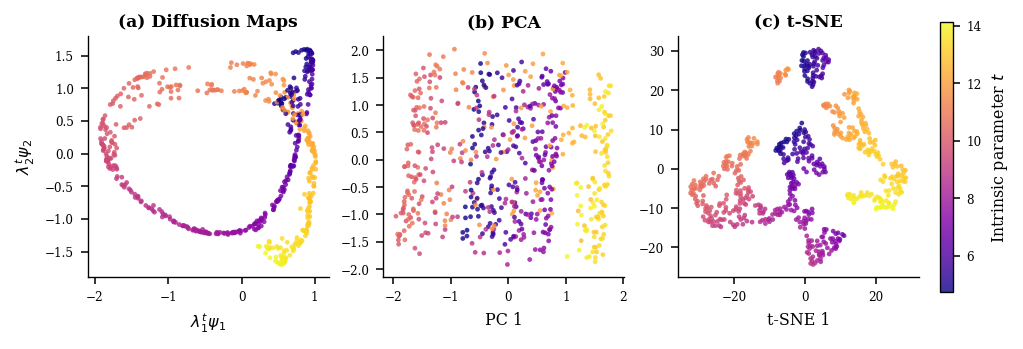

Saved: /content/pictures/swiss_roll_embeddings.pdf


In [46]:
# ── Swiss Roll embeddings ─────────────────────────────────────────────────
swiss_norm = mcolors.Normalize(vmin=t_sr.min(), vmax=t_sr.max())
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.55), constrained_layout=True)

for panel, method in enumerate(METHOD_ORDER):
    embedding = EMBEDDINGS_SR[method]
    x_label, y_label = AXIS_LABELS[method]
    sc = axes[panel].scatter(embedding[:, 0], embedding[:, 1], c=t_sr, cmap='plasma', norm=swiss_norm, s=6, alpha=0.82, linewidths=0, rasterized=True)
    axes[panel].set_title(f'({chr(97 + panel)}) {method}', fontweight='bold', pad=5)
    axes[panel].set_xlabel(x_label)
    axes[panel].set_ylabel(y_label if panel == 0 else '')
    axes[panel].tick_params(labelsize=6.2)
    axes[panel].set_box_aspect(1)
    axes[panel].margins(x=0.06, y=0.06)

colorbar = fig.colorbar(sc, ax=axes.ravel().tolist(), fraction=0.030, pad=0.025, shrink=0.82)
colorbar.set_label(r'Intrinsic parameter $t$')
colorbar.ax.tick_params(labelsize=6.2)
swiss_path = os.path.join(OUTPUT_DIR, 'swiss_roll_embeddings.pdf')
fig.savefig(swiss_path, dpi=600, bbox_inches='tight', pad_inches=0.05, facecolor='white')
plt.show()
print('Saved:', swiss_path)

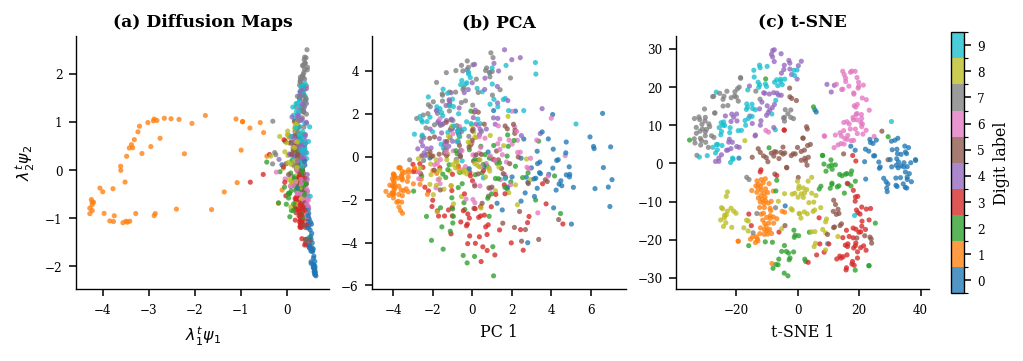

Saved: /content/pictures/mnist_embeddings.pdf


In [47]:
# ── MNIST embeddings ──────────────────────────────────────────────────────
digit_cmap = plt.get_cmap('tab10', 10)
digit_norm = mcolors.BoundaryNorm(np.arange(-0.5, 10.5, 1.0), digit_cmap.N)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.55), constrained_layout=True)

for panel, method in enumerate(METHOD_ORDER):
    embedding = EMBEDDINGS_MNIST[method]
    x_label, y_label = AXIS_LABELS[method]
    sc = axes[panel].scatter(embedding[:, 0], embedding[:, 1], c=y_mnist, cmap=digit_cmap, norm=digit_norm, s=7, alpha=0.78, linewidths=0, rasterized=True)
    axes[panel].set_title(f'({chr(97 + panel)}) {method}', fontweight='bold', pad=5)
    axes[panel].set_xlabel(x_label)
    axes[panel].set_ylabel(y_label if panel == 0 else '')
    axes[panel].tick_params(labelsize=6.2)
    axes[panel].set_box_aspect(1)
    axes[panel].margins(x=0.06, y=0.06)

colorbar = fig.colorbar(sc, ax=axes.ravel().tolist(), ticks=np.arange(10), fraction=0.030, pad=0.025, shrink=0.82)
colorbar.set_label('Digit label')
colorbar.ax.tick_params(labelsize=6.2)
mnist_path = os.path.join(OUTPUT_DIR, 'mnist_embeddings.pdf')
fig.savefig(mnist_path, dpi=600, bbox_inches='tight', pad_inches=0.05, facecolor='white')
plt.show()
print('Saved:', mnist_path)

## 4.4. Tiêu chí đánh giá

Không có một chỉ số duy nhất phản ánh đầy đủ chất lượng giảm chiều. Thực nghiệm sử dụng bốn tiêu chí bổ sung cho nhau.

### Bảo toàn lân cận

Với $\mathcal{N}_k^X(i)$ và $\mathcal{N}_k^Y(i)$ là tập $k$ láng giềng gần nhất của điểm $i$ trong không gian tham chiếu và không gian biểu diễn, tỷ lệ bảo toàn được xác định bởi

$$
\operatorname{Overlap}_k=\frac{1}{n}\sum_{i=1}^{n}\frac{|\mathcal{N}_k^X(i)\cap\mathcal{N}_k^Y(i)|}{k}.
$$

Chỉ số được khảo sát với $k=1,\ldots,20$.

### Trustworthiness

Trustworthiness tại $k=10$ đo mức độ các điểm không phải láng giềng trong không gian tham chiếu trở thành láng giềng trong biểu diễn. Giá trị gần 1 biểu thị ít quan hệ lân cận sai lệch hơn.

### Tương quan thứ hạng khoảng cách

Hệ số Spearman được tính giữa khoảng cách cặp trong không gian tham chiếu và trong biểu diễn hai chiều trên cùng tập con 300 điểm. Với Swiss Roll, không gian tham chiếu là $(s(t),h)$; với MNIST, đó là không gian điểm ảnh 784 chiều.

### Điểm phân tách 5-NN trên MNIST

Bộ phân loại 5-NN được đánh giá bằng kiểm định chéo phân tầng năm phần trên embedding đã được xây dựng từ toàn bộ 600 mẫu. Vì vậy, đây là chỉ số phân tách chuyển dẫn, không phải đánh giá suy luận ngoài mẫu.

In [48]:
# ── Quantitative evaluation ───────────────────────────────────────────────
def knn_overlap_curve(X_reference, X_embedding, ks):
    max_k = int(np.max(ks))
    original_neighbors = NearestNeighbors(n_neighbors=max_k + 1, algorithm='auto', n_jobs=-1).fit(X_reference).kneighbors(X_reference, return_distance=False)[:, 1:]
    embedded_neighbors = NearestNeighbors(n_neighbors=max_k + 1, algorithm='auto', n_jobs=-1).fit(X_embedding).kneighbors(X_embedding, return_distance=False)[:, 1:]
    return np.asarray([np.mean([len(set(original_neighbors[i, :k]) & set(embedded_neighbors[i, :k])) / k for i in range(len(X_reference))]) for k in ks])

def distance_rank_correlation(X_reference, X_embedding, n_sub=300, seed=SEED):
    local_rng = np.random.default_rng(seed)
    n_use = min(n_sub, len(X_reference))
    indices = local_rng.choice(len(X_reference), size=n_use, replace=False)
    reference_distances = pdist(X_reference[indices], metric='euclidean')
    embedding_distances = pdist(X_embedding[indices], metric='euclidean')
    return float(spearmanr(reference_distances, embedding_distances).statistic)

def transductive_knn_score(X_embedding, labels, seed=SEED):
    model = KNeighborsClassifier(n_neighbors=5)
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    scores = cross_val_score(model, X_embedding, labels, cv=folds, scoring='accuracy', n_jobs=-1)
    return float(scores.mean()), float(scores.std())

KS = np.arange(1, 21)
OVERLAP_CURVES = {'Swiss Roll': {}, 'MNIST': {}}
RESULT_ROWS = []

for dataset_name, X_reference, embeddings, labels in [('Swiss Roll', X_sr_reference, EMBEDDINGS_SR, None), ('MNIST', X_mnist, EMBEDDINGS_MNIST, y_mnist)]:
    for method, embedding in embeddings.items():
        curve = knn_overlap_curve(X_reference, embedding, KS)
        OVERLAP_CURVES[dataset_name][method] = curve
        trust = float(trustworthiness(X_reference, embedding, n_neighbors=10))
        rho = distance_rank_correlation(X_reference, embedding, n_sub=300, seed=SEED)
        score_mean, score_std = (np.nan, np.nan) if labels is None else transductive_knn_score(embedding, labels, seed=SEED)
        RESULT_ROWS.append({'Dataset': dataset_name, 'Method': method, 'Mean kNN overlap': float(curve.mean()), 'Trustworthiness@10': trust, 'Spearman rho': rho, 'Transductive 5-NN score': score_mean, '5-NN score std': score_std, 'Runtime (s)': RUNTIMES[dataset_name][method]})

results_df = pd.DataFrame(RESULT_ROWS)
display(results_df.round(4))

,Dataset,Method,Mean kNN overlap,Trustworthiness@10,Spearman rho,Transductive 5-NN score,5-NN score std,Runtime (s)
0,Swiss Roll,Diffusion Maps,0.4393,0.9046,0.2908,NaN,NaN,0.1330
1,Swiss Roll,PCA,0.4218,0.7940,0.3411,NaN,NaN,0.0011
2,Swiss Roll,t-SNE,0.8341,0.9990,0.4175,NaN,NaN,2.2765
3,MNIST,Diffusion Maps,0.2137,0.7777,0.1521,0.4700,0.0417,0.1760
4,MNIST,PCA,0.1551,0.7324,0.5096,0.3933,0.0271,0.0825
5,MNIST,t-SNE,0.5423,0.9450,0.4634,0.8133,0.0282,3.1715


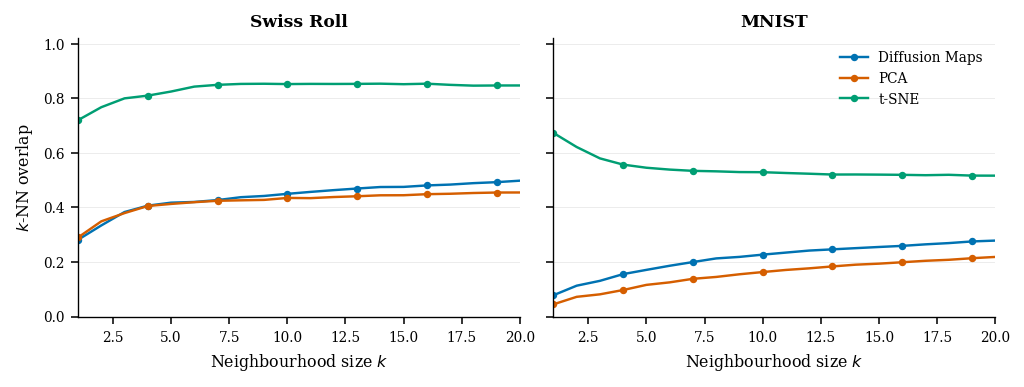

Saved: /content/pictures/knn_overlap.pdf


In [49]:
# ── k-NN overlap curves ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.65), sharey=True, constrained_layout=True)

for ax, dataset_name in zip(axes, ['Swiss Roll', 'MNIST']):
    for method in METHOD_ORDER:
        ax.plot(KS, OVERLAP_CURVES[dataset_name][method], color=METHOD_COLORS[method], linewidth=1.25, marker='o', markersize=2.8, markevery=3, label=method)
    ax.set_xlabel(r'Neighbourhood size $k$')
    ax.set_title(dataset_name, fontweight='bold')
    ax.set_xlim(1, 20)
    ax.set_ylim(0, 1.02)
    ax.grid(axis='y', linewidth=0.35, alpha=0.35)

axes[0].set_ylabel(r'$k$-NN overlap')
axes[1].legend(frameon=False, loc='best')
overlap_path = os.path.join(OUTPUT_DIR, 'knn_overlap.pdf')
fig.savefig(overlap_path, dpi=600, bbox_inches='tight', pad_inches=0.05, facecolor='white')
plt.show()
print('Saved:', overlap_path)

## 4.5. Tổng hợp và diễn giải kết quả

Các chỉ số được diễn giải riêng theo thuộc tính mà chúng đo. Giá trị lớn nhất không chứng minh một phương pháp tốt hơn trên mọi mục tiêu.

- k-NN overlap và trustworthiness ưu tiên khả năng bảo toàn cấu trúc cục bộ, phù hợp với mục tiêu của t-SNE.
- Spearman $\rho$ phản ánh mức bảo toàn thứ hạng khoảng cách nhưng không đo trực tiếp diffusion distance.
- Điểm 5-NN phản ánh mức phân tách nhãn trong embedding MNIST; đây không phải mục tiêu tối ưu trực tiếp của Diffusion Maps.
- Thời gian của Diffusion Maps bao gồm dựng đồ thị 64-NN, tính thang cục bộ, chọn $\varepsilon$ bằng BGH và phân rã phổ; thời gian của PCA và t-SNE bao gồm bước khớp mô hình. Các giá trị chỉ có ý nghĩa trong cùng phiên chạy và cùng môi trường phần cứng.

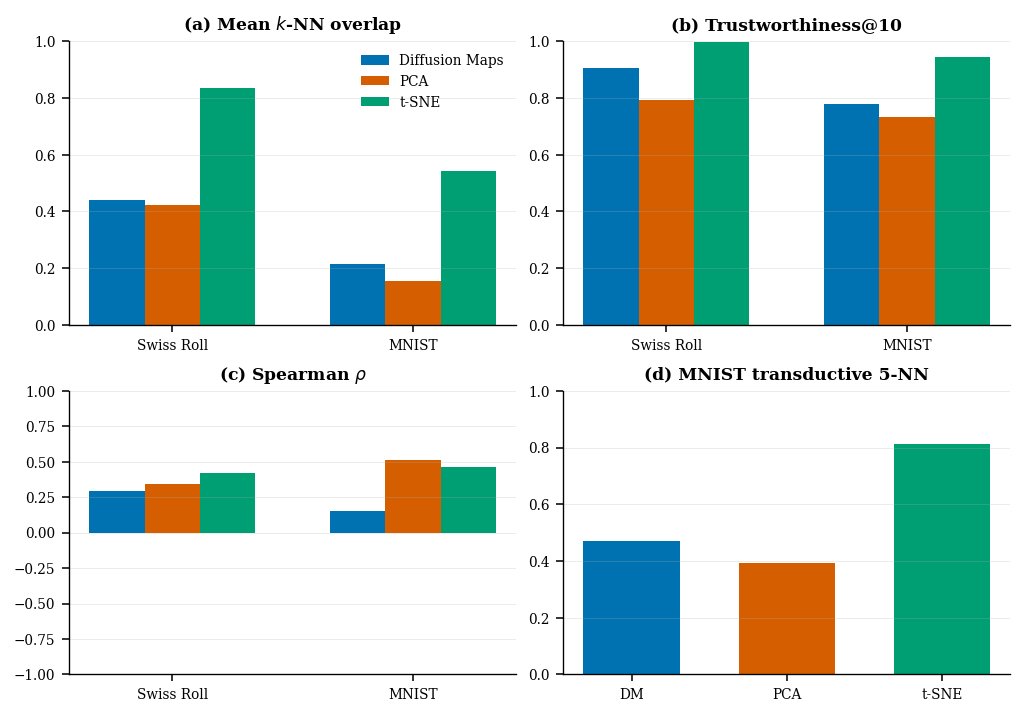

Saved: /content/pictures/quantitative_summary.pdf
Saved: /content/pictures/quantitative_results.csv


In [50]:
# ── Quantitative summary ──────────────────────────────────────────────────
def grouped_metric_bars(ax, dataframe, metric, title, ylim=(0.0, 1.0)):
    datasets = ['Swiss Roll', 'MNIST']
    x = np.arange(len(datasets))
    width = 0.23
    for index, method in enumerate(METHOD_ORDER):
        values = [float(dataframe[(dataframe['Dataset'] == dataset) & (dataframe['Method'] == method)][metric].iloc[0]) for dataset in datasets]
        ax.bar(x + (index - 1) * width, values, width=width, color=METHOD_COLORS[method], label=method)
    ax.set_xticks(x)
    ax.set_xticklabels(datasets)
    ax.set_ylim(*ylim)
    ax.set_title(title, fontweight='bold')
    ax.grid(axis='y', linewidth=0.35, alpha=0.35)

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.0), constrained_layout=True)
grouped_metric_bars(axes[0, 0], results_df, 'Mean kNN overlap', r'(a) Mean $k$-NN overlap')
grouped_metric_bars(axes[0, 1], results_df, 'Trustworthiness@10', '(b) Trustworthiness@10')
grouped_metric_bars(axes[1, 0], results_df, 'Spearman rho', r'(c) Spearman $\rho$', ylim=(-1.0, 1.0))
axes[0, 0].legend(frameon=False, loc='upper right')

mnist_rows = results_df[results_df['Dataset'] == 'MNIST'].set_index('Method').loc[METHOD_ORDER]
axes[1, 1].bar(np.arange(3), mnist_rows['Transductive 5-NN score'].values, color=[METHOD_COLORS[method] for method in METHOD_ORDER], width=0.62)
axes[1, 1].set_xticks(np.arange(3))
axes[1, 1].set_xticklabels(['DM', 'PCA', 't-SNE'])
axes[1, 1].set_ylim(0.0, 1.0)
axes[1, 1].set_title('(d) MNIST transductive 5-NN', fontweight='bold')
axes[1, 1].grid(axis='y', linewidth=0.35, alpha=0.35)

summary_path = os.path.join(OUTPUT_DIR, 'quantitative_summary.pdf')
results_path = os.path.join(OUTPUT_DIR, 'quantitative_results.csv')
fig.savefig(summary_path, dpi=600, bbox_inches='tight', pad_inches=0.05, facecolor='white')
results_df.to_csv(results_path, index=False)
plt.show()
print('Saved:', summary_path)
print('Saved:', results_path)

In [51]:
# ── Metric-wise ranking ───────────────────────────────────────────────────
METRICS = ['Mean kNN overlap', 'Trustworthiness@10', 'Spearman rho', 'Transductive 5-NN score']
ranking_rows = []

for dataset_name in ['Swiss Roll', 'MNIST']:
    dataset_results = results_df[results_df['Dataset'] == dataset_name]
    for metric in METRICS:
        ranking = dataset_results[['Method', metric]].dropna().sort_values(metric, ascending=False).reset_index(drop=True)
        if len(ranking) >= 2:
            ranking_rows.append({'Dataset': dataset_name, 'Metric': metric, 'Best method': ranking.loc[0, 'Method'], 'Best score': ranking.loc[0, metric], 'Runner-up': ranking.loc[1, 'Method'], 'Margin': ranking.loc[0, metric] - ranking.loc[1, metric]})

ranking_df = pd.DataFrame(ranking_rows)
display(ranking_df.round(4))

,Dataset,Metric,Best method,Best score,Runner-up,Margin
0,Swiss Roll,Mean kNN overlap,t-SNE,0.8341,Diffusion Maps,0.3948
1,Swiss Roll,Trustworthiness@10,t-SNE,0.9990,Diffusion Maps,0.0944
2,Swiss Roll,Spearman rho,t-SNE,0.4175,PCA,0.0764
3,MNIST,Mean kNN overlap,t-SNE,0.5423,Diffusion Maps,0.3287
4,MNIST,Trustworthiness@10,t-SNE,0.9450,Diffusion Maps,0.1673
5,MNIST,Spearman rho,PCA,0.5096,t-SNE,0.0462
6,MNIST,Transductive 5-NN score,t-SNE,0.8133,Diffusion Maps,0.3433


## 4.6. Kết luận và giới hạn

Thực nghiệm không giả định Diffusion Maps phải đứng đầu mọi tiêu chí. Phương pháp xây dựng tọa độ từ diffusion distance, trong khi t-SNE tối ưu trực tiếp cấu trúc lân cận và PCA tối ưu phương sai tuyến tính. Vì vậy, thứ hạng phụ thuộc vào thuộc tính được đánh giá.

Các giới hạn chính gồm:

1. Băng thông BGH là một thủ tục lựa chọn không giám sát nhưng vẫn phụ thuộc vào miền lưới $\varepsilon$.
2. Kernel băng thông cục bộ làm giảm eigenvector định vị do mật độ mẫu không đồng đều nhưng bổ sung tham số số láng giềng dùng để xác định $\rho_i$.
3. Điểm 5-NN trên MNIST là đánh giá chuyển dẫn, không phải khả năng ánh xạ mẫu mới.
4. Kernel đầy đủ cần $O(n^2)$ bộ nhớ và phép phân rã phổ trở nên tốn kém khi số mẫu tăng.
5. Kết quả sử dụng một seed và tập con 600 mẫu, nên chưa biểu thị độ biến thiên qua nhiều lần lấy mẫu.

Do đó, hình biểu diễn đẹp hơn không được xem là bằng chứng duy nhất về chất lượng. Kết luận phải dựa đồng thời trên mục tiêu của phương pháp, các chỉ số định lượng và giới hạn của thiết kế thực nghiệm.

### Tài liệu phương pháp

- Coifman, R. R., & Lafon, S. (2006). *Diffusion maps*. Applied and Computational Harmonic Analysis, 21(1), 5–30.
- Berry, T., Giannakis, D., & Harlim, J. (2015). *Nonparametric forecasting of low-dimensional dynamical systems*. Physical Review E, 91, 032915.
- Berry, T., & Harlim, J. (2016). *Variable bandwidth diffusion kernels*. Applied and Computational Harmonic Analysis, 40(1), 68–96.
- Coifman, R. R., Shkolnisky, Y., Sigworth, F. J., & Singer, A. (2008). *Graph Laplacian tomography from unknown random projections*. IEEE Transactions on Image Processing, 17(10), 1891–1899.
- Dsilva, C. J., Talmon, R., Coifman, R. R., & Kevrekidis, I. G. (2018). *Parsimonious representation of nonlinear dynamical systems through manifold learning*. Applied and Computational Harmonic Analysis, 44(3), 759–773.